In [ ]:
import json

import duckdb
import pandas as pd

con = duckdb.connect("/Users/phillip/repositories/bachelor-thesis/data/ablation/manifest.duckdb", read_only=True)
df = con.execute("SELECT * FROM samples ORDER BY sample_id").fetchdf()
# df.shape


df["displacement_role"].value_counts()
df.groupby(["marker_shape", "marker_color"]).size()
df["target_signed_edge_distance_m"].value_counts(dropna=False).sort_index()
df.groupby("ecoregion_code")["building_id"].nunique()
df["ground_truth_inside"].value_counts()

ground_truth_inside
False    6075
True     3033
Name: count, dtype: int64

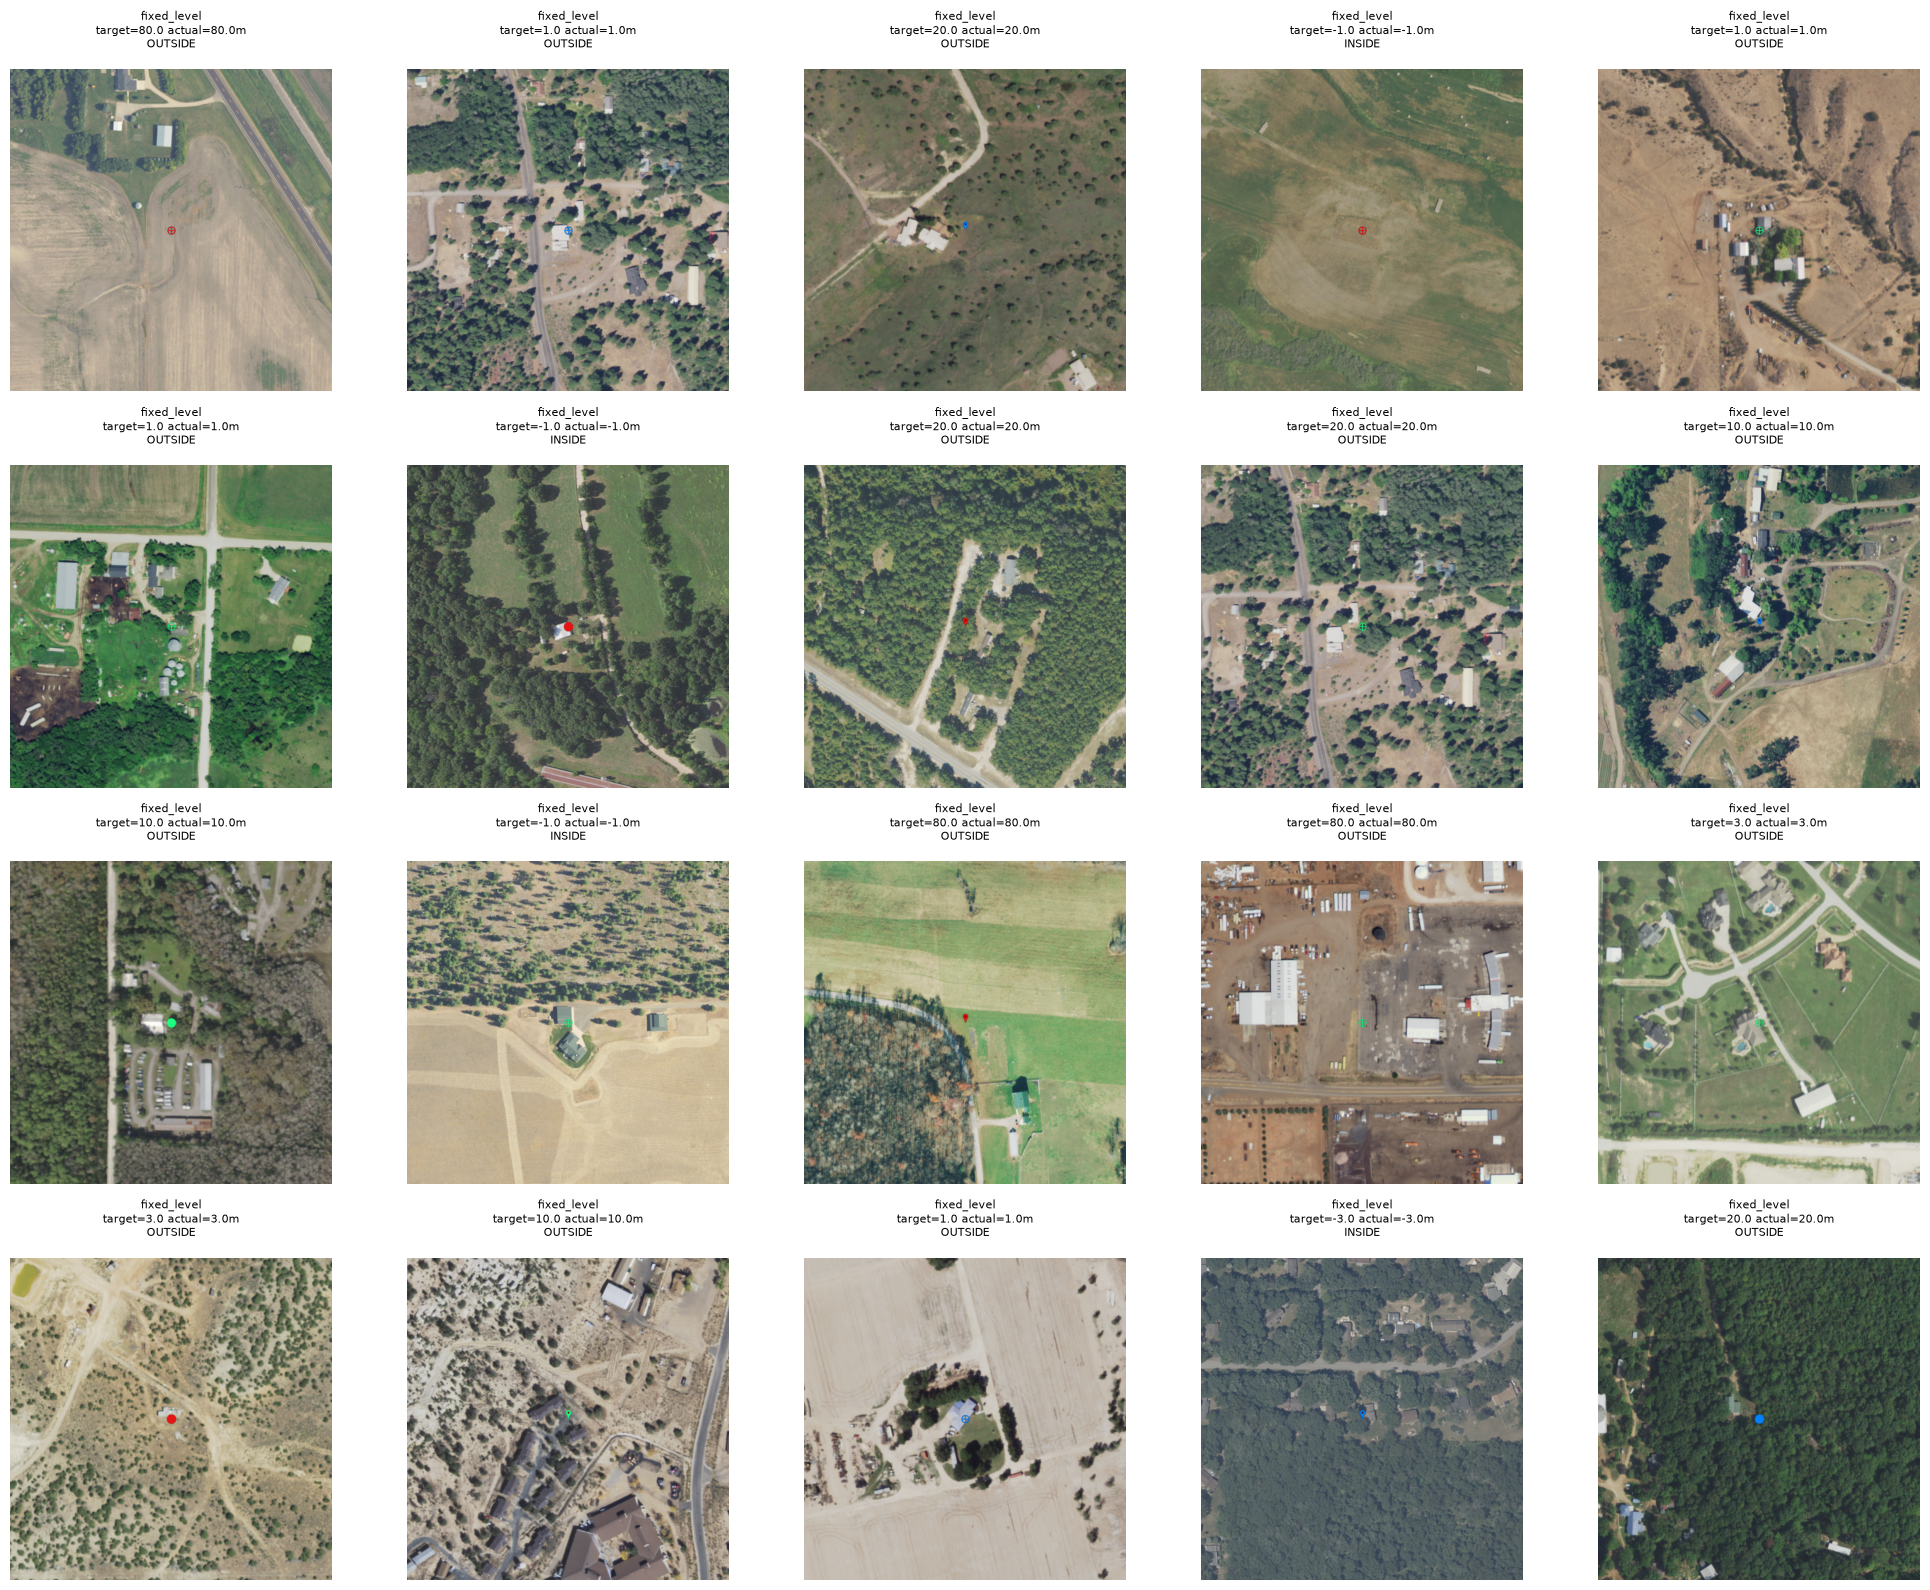

In [ ]:
import matplotlib.image as mpimg
import matplotlib.pyplot as plt

sample = df.sample(20, random_state=1)
fig, axes = plt.subplots(4, 5, figsize=(20, 16))
for ax, (_, row) in zip(axes.flat, sample.iterrows(), strict=False):
    img = mpimg.imread(f"/Users/phillip/repositories/bachelor-thesis/data/ablation/{row['image_path']}")
    ax.imshow(img)
    label = "INSIDE" if row["ground_truth_inside"] else "OUTSIDE"
    ax.set_title(
        f"{row['displacement_role']}\n"
        f"target={row['target_signed_edge_distance_m']} actual={row['actual_signed_edge_distance_m']:.1f}m\n"
        f"{label}\n",
        fontsize=8,
    )
    ax.axis("off")
plt.tight_layout()

In [12]:
failures = pd.DataFrame(json.load(open("/Users/phillip/repositories/bachelor-thesis/data/ablation/failures.json")))
failures["stage"].value_counts()


def bucket(reason):
    if "No items with GSD" in reason:
        return "no_gsd_match"
    if "out of bounds" in reason:
        return "tile_out_of_bounds"
    return reason


failures["bucket"] = failures["reason"].map(bucket)
print(failures.groupby(["stage", "bucket"]).size())

id = df["building_id"].iloc[0]
(
    df[(df.building_id == id) & (df.marker_shape == "google_pin") & (df.marker_color == "(230, 20, 20)")].sort_values(
        "target_signed_edge_distance_m", na_position="last"
    )[
        [
            "displacement_role",
            "target_signed_edge_distance_m",
            "actual_signed_edge_distance_m",
            "radial_displacement_m",
            "bearing_radians",
            "ground_truth_inside",
        ]
    ]
)

stage         bucket                        
displacement  pin_on_other_footprint             419
              target_or_anchor_outside_image      39
              unreachable_negative_level        1142
naip_fetch    no_gsd_match                       215
              tile_out_of_bounds                1252
dtype: int64


,displacement_role,target_signed_edge_distance_m,actual_signed_edge_distance_m,radial_displacement_m,bearing_radians,ground_truth_inside
792,fixed_level,-3.0,-3.000000,4.665248,3.979179,True
7397,fixed_level,-1.0,-1.000000,6.667022,3.979179,True
1480,fixed_level,1.0,1.000000,8.668796,3.979179,False
7370,fixed_level,3.0,3.000000,10.670570,3.979179,False
4275,fixed_level,5.0,5.000000,12.672344,3.979179,False
2791,fixed_level,10.0,10.000000,17.676778,3.979179,False
2253,fixed_level,20.0,20.000000,27.685648,3.979179,False
7070,fixed_level,40.0,40.000000,47.703387,3.979179,False
5450,fixed_level,80.0,80.000000,87.738865,3.979179,False
7382,deep_inside_control,NaN,-4.739439,0.193196,NaN,True
